# Tu cartera: activos reales y configuración editable

Define los activos, sus fuentes, el periodo, el capital y los pesos. Los datos se descargan mediante
**AssetFetcher**; la construcción y los cálculos los realizan **Portfolio**, **Position** y **Transaction**.
Este notebook es una prueba de integración, no `main`. No contiene cotizaciones ficticias ni resultados precargados.

Guárdalo en `tests/`, selecciona tu entorno virtual y ejecuta las celdas en orden.
Necesita la nueva versión de Portfolio con capital, posiciones y efectivo.
Las claves de API se leen de `.env` y no se muestran.

## 1. Importar las clases del proyecto

In [9]:
import sys
import os
import importlib
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv

project_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "financial_toolkit").is_dir()),
    Path(r"C:\Users\Javie\Desktop\Estudios\MIAX\Financial-Toolkit"),
)
models_path = project_root / "src" / "financial_toolkit"
assert models_path.is_dir(), "Ajusta project_root a tu carpeta Financial-Toolkit"
sys.path.insert(0, str(models_path.parent))
load_dotenv(project_root / ".env", override=True)

from financial_toolkit import asset_fetcher
importlib.reload(asset_fetcher)
# En uso normal se carga el archivo del proyecto. La variable opcional
# permite validar una versión preparada antes de instalarla.
portfolio_file = Path(os.getenv("PORTFOLIO_SOURCE", str(models_path / "portfolio.py")))
spec = importlib.util.spec_from_file_location("financial_toolkit.portfolio", portfolio_file)
portfolio = importlib.util.module_from_spec(spec)
sys.modules["financial_toolkit.portfolio"] = portfolio
spec.loader.exec_module(portfolio)
AssetFetcher = asset_fetcher.AssetFetcher
Portfolio = portfolio.Portfolio
assert "capital" in getattr(Portfolio, "__dataclass_fields__", {}), (
    "Instala primero la versión nueva de portfolio.py en src/financial_toolkit"
)
assert hasattr(Portfolio, "deposit") and hasattr(Portfolio, "sampling_info"), (
    "Actualiza portfolio.py y añade cash_movement.py antes de ejecutar esta versión"
)

def table(frame, money=(), percentages=(), units=()):
    formats = {column: "{:,.2f}" for column in money}
    formats.update({column: "{:.2%}" for column in percentages})
    formats.update({column: "{:,.6f}" for column in units})
    display(frame.style.format(formats, na_rep="Sin dato"))

print("Portfolio:", portfolio.__file__)
print("AssetFetcher:", asset_fetcher.__file__)

Portfolio: c:\Users\Javie\Desktop\Estudios\MIAX\Financial-Toolkit\src\models\portfolio.py
AssetFetcher: c:\Users\Javie\Desktop\Estudios\MIAX\Financial-Toolkit\src\models\asset_fetcher.py


## 2. Configuración: cambia aquí tu ejemplo

Las fechas se eligen una sola vez. Los pesos se introducen aparte de las solicitudes y usan el símbolo solicitado
(`bitcoin`, aunque CoinGecko devuelva el identificador `btc`).

- `1/3` en cada activo: tres partes iguales. `0.33` en cada uno deja un 1 % de efectivo.
- Un peso negativo abre un corto. Una suma mayor que uno puede necesitar deuda.
- Todos los precios deben estar en USD; todavía no se convierten divisas.
- `fecha_compra = None` elige y **muestra** el primer día del periodo con precios observados para todos los activos con peso distinto de cero.
  Para elegirla tú, sustituye `None` por una fecha. Si falta un precio ese día, la creación se detiene sin cambiarte la fecha.

El ejemplo inicial usa Apple, S&P 500 y Bitcoin, con un tercio para cada uno. El índice se trata como una posición simulada;
no representa la compra directa de un instrumento negociable.

In [10]:
solicitudes = [
    {"symbol": "AAPL", "type": "stock", "api": "yfinance"},
    {"symbol": "^GSPC", "type": "index", "api": "yfinance"},
    {"symbol": "bitcoin", "type": "crypto", "api": "coingecko",
     "params": {"currency": "usd"}},
]

periodo = {"start": "2026-10-01", "end": "2026-10-30"}
capital_inicial = 10_000
pesos = {"AAPL": 1/3, "^GSPC": 1/3, "bitcoin": 1/3}
fecha_compra = None

# Movimientos posteriores, en orden cronológico. Edita esta lista.
# Descomenta ejemplos solo después de revisar las fechas disponibles.
movimientos = [
    # {"tipo": "DEPOSIT", "importe": 1000, "fecha": "2026-10-06"},
    # {"tipo": "BUY", "activo": "AAPL", "cantidad": 1, "fecha": "2026-10-08"},
    # {"tipo": "SELL", "activo": "AAPL", "cantidad": 1, "fecha": "2026-10-10"},
    # {"tipo": "WITHDRAW", "importe": 500, "fecha": "2026-10-14"},
]

# Para probar largos, cortos y efectivo, puedes cambiar los pesos:
# pesos = {"AAPL": 0.8, "^GSPC": 0.4, "bitcoin": -0.2}

symbols = [request["symbol"] for request in solicitudes]
assert len(symbols) == len(set(symbols)), "No repitas símbolos en esta prueba"
assert set(pesos) == set(symbols), "Debe haber un peso para cada solicitud"
assert all(not isinstance(pesos[s], bool) and np.isfinite(pesos[s]) for s in symbols)
assert np.isfinite(capital_inicial) and capital_inicial > 0
assert any(pesos[s] != 0 for s in symbols), "Elige al menos un activo con peso distinto de cero"

configuration = pd.DataFrame([
    {"Activo solicitado": r["symbol"], "Tipo": r["type"], "API": r["api"],
     "Peso objetivo": pesos[r["symbol"]],
     "Importe objetivo USD": capital_inicial * pesos[r["symbol"]]}
    for r in solicitudes
])
table(configuration, money=["Importe objetivo USD"], percentages=["Peso objetivo"])
print(f"Periodo solicitado: {periodo['start']} a {periodo['end']}")
print(f"Capital inicial: {capital_inicial:,.2f} USD")
print(f"Efectivo objetivo: {capital_inicial * (1 - sum(pesos.values())):,.2f} USD")

,Activo solicitado,Tipo,API,Peso objetivo,Importe objetivo USD
0,AAPL,stock,yfinance,33.33%,"3,333.33"
1,^GSPC,index,yfinance,33.33%,"3,333.33"
2,bitcoin,crypto,coingecko,33.33%,"3,333.33"


Periodo solicitado: 2026-10-01 a 2026-10-30
Capital inicial: 10,000.00 USD
Efectivo objetivo: 0.00 USD


## 3. Descargar mediante AssetFetcher

Esta celda realiza llamadas reales y puede tardar o fallar por permisos, claves, límites o cobertura de las fuentes.
Al cambiar solo los pesos o el capital no necesitas repetir la descarga: ejecuta desde la sección 4.
Al cambiar las solicitudes o el periodo, ejecuta desde esta sección.

In [11]:
from copy import deepcopy

fetcher = AssetFetcher()
activos = fetcher.get_many(solicitudes, **periodo)
assert len(activos) == len(solicitudes)
downloaded_requests = deepcopy(solicitudes)
downloaded_period = periodo.copy()
print(f"Descargados {len(activos)} activos.")

Descargados 3 activos.


## 4. Qué hemos descargado y qué días hay realmente

La tabla permite comprobar los identificadores, fuentes, pesos y cobertura. Se conserva el último precio observado
de cada día para inspeccionar la disponibilidad; esta agrupación no crea observaciones.
No se rellenan huecos de cripto. Con la consulta OHLC actual de CoinGecko pueden aparecer puntos cada cuatro días.

In [12]:
assert solicitudes == downloaded_requests and periodo == downloaded_period, (
    "Has cambiado activos o fechas: repite la descarga de la sección 3"
)
assert set(pesos) == {r["symbol"] for r in solicitudes}, "Revisa los pesos"
calendar = pd.date_range(periodo["start"], periodo["end"], freq="D")
observados = {}
rows = []
ids = []
for request, asset in zip(solicitudes, activos):
    symbol = request["symbol"]
    identifier = getattr(asset, "ticker", None) or asset.symbol
    ids.append(identifier)
    if getattr(asset, "price", None) is None:
        raise ValueError(f"{symbol} no tiene precios: los tipos de bonos no permiten valorar una posición")
    values = asset.price.close.copy().sort_index()
    values.index = pd.DatetimeIndex(values.index).tz_localize(None)
    daily = values.resample("D").last().reindex(calendar)
    observados[identifier] = daily
    known = daily.dropna()
    rows.append({
        "Solicitado": symbol, "Identificador": identifier, "Clase": type(asset).__name__,
        "API": request["api"], "Peso objetivo": pesos[symbol],
        "Días con observación": len(known), "Días sin observación": int(daily.isna().sum()),
        "Primera observación": known.index.min(), "Última observación": known.index.max(),
    })

assert len(ids) == len(set(ids)), "Dos objetos tienen el mismo identificador"
table(pd.DataFrame(rows), percentages=["Peso objetivo"])
observados = pd.DataFrame(observados)
table(observados, money=list(observados.columns))

,Solicitado,Identificador,Clase,API,Peso objetivo,Días con observación,Días sin observación,Primera observación,Última observación
0,AAPL,AAPL,Stock,yfinance,33.33%,22,8,2026-10-01 00:00:00,2026-10-30 00:00:00
1,^GSPC,^GSPC,Index,yfinance,33.33%,22,8,2026-10-01 00:00:00,2026-10-30 00:00:00
2,bitcoin,btc,Cryptocurrency,coingecko,33.33%,8,22,2026-10-02 00:00:00,2026-10-30 00:00:00


,AAPL,^GSPC,btc
2026-10-01 00:00:00,330.32,"7,666.45",Sin dato
2026-10-02 00:00:00,333.69,"7,722.72","84,842.00"
2026-10-03 00:00:00,Sin dato,Sin dato,Sin dato
2026-10-04 00:00:00,Sin dato,Sin dato,Sin dato
2026-10-05 00:00:00,332.89,"7,773.95",Sin dato
2026-10-06 00:00:00,333.63,"7,818.93","85,771.00"
2026-10-07 00:00:00,336.67,"7,801.77",Sin dato
2026-10-08 00:00:00,340.42,"7,765.36",Sin dato
2026-10-09 00:00:00,336.64,"7,811.54",Sin dato
2026-10-10 00:00:00,Sin dato,Sin dato,"82,563.00"


## 5. Elegir la fecha y construir la cartera

La fecha seleccionada y las alternativas se muestran antes de crearla. Se usan precios observados comunes para que
las compras iniciales puedan comprobarse sin arrastrar un precio anterior. A partir de ahí, Portfolio aplica su política
de valoración: último cierre para bolsa; los huecos de cripto permanecen como datos ausentes.

In [13]:
weights_by_id = {identifier: pesos[r["symbol"]] for identifier, r in zip(ids, solicitudes)}
active_ids = [identifier for identifier in ids if weights_by_id[identifier] != 0]
available = observados[active_ids].dropna(how="any").index
print("Fechas con observaciones comunes:", ", ".join(available.strftime("%Y-%m-%d")))
assert len(available), "No hay fechas comunes: cambia periodo o fuente"
selected_date = available[0] if fecha_compra is None else pd.Timestamp(fecha_compra).normalize()
assert selected_date in available, (
    "Falta una observación en la fecha elegida. Selecciona una de las fechas mostradas"
)
print("Fecha efectiva de compra:", selected_date.date())

cartera = Portfolio.from_weights(
    assets=activos,
    weights=weights_by_id,
    capital=capital_inicial,
    date=selected_date,
)

initial = []
for identifier, request in zip(ids, solicitudes):
    position = cartera.positions.get(identifier)
    initial.append({
        "Activo": request["symbol"], "Identificador": identifier,
        "Dirección": "Largo" if weights_by_id[identifier] > 0 else (
            "Corto" if weights_by_id[identifier] < 0 else "Sin posición"),
        "Peso objetivo": weights_by_id[identifier],
        "Unidades": 0 if position is None else position.quantity,
        "Precio entrada USD": np.nan if position is None else position.average_price,
        "Valor firmado USD": 0 if position is None else position.market_value,
    })
table(pd.DataFrame(initial), money=["Precio entrada USD", "Valor firmado USD"],
      percentages=["Peso objetivo"], units=["Unidades"])

transactions = pd.DataFrame([
    {"Fecha": t.date, "Activo": getattr(t.asset, "ticker", None) or t.asset.symbol,
     "Operación": t.transaction_type, "Unidades": t.quantity,
     "Precio USD": t.price, "Flujo efectivo USD": t.cash_flow}
    for t in cartera.transactions
])
table(transactions, money=["Precio USD", "Flujo efectivo USD"], units=["Unidades"])

Fechas con observaciones comunes: 2026-10-02, 2026-10-06, 2026-10-14, 2026-10-22, 2026-10-26, 2026-10-30
Fecha efectiva de compra: 2026-10-02


,Activo,Identificador,Dirección,Peso objetivo,Unidades,Precio entrada USD,Valor firmado USD
0,AAPL,AAPL,Largo,33.33%,9.989311,333.69,"3,333.33"
1,^GSPC,^GSPC,Largo,33.33%,0.431627,"7,722.72","3,333.33"
2,bitcoin,btc,Largo,33.33%,0.039289,"84,842.00","3,333.33"


,Fecha,Activo,Operación,Unidades,Precio USD,Flujo efectivo USD
0,2026-10-02 00:00:00,AAPL,BUY,9.989311,333.69,"-3,333.33"
1,2026-10-02 00:00:00,^GSPC,BUY,0.431627,"7,722.72","-3,333.33"
2,2026-10-02 00:00:00,btc,BUY,0.039289,"84,842.00","-3,333.33"


## 6. Comprobar tu cartera inicial

Se contrastan las cantidades, pesos, efectivo y patrimonio contra las instrucciones introducidas.
Las cifras se muestran con formato legible; las comprobaciones usan los valores completos y tolerancias numéricas.

In [14]:
checks = []
initial_prices = observados.loc[selected_date]
expected_units = pd.Series({
    identifier: capital_inicial * weights_by_id[identifier] / initial_prices[identifier]
    for identifier in active_ids
})
obtained_units = pd.Series(cartera.quantities).reindex(active_ids)
np.testing.assert_allclose(obtained_units, expected_units, rtol=1e-10, atol=1e-12)
checks.append({"Comprobación": "Unidades = capital × peso / precio", "Estado": "OK"})

expected_cash = capital_inicial * (1 - sum(weights_by_id.values()))
np.testing.assert_allclose(cartera.cash, expected_cash, rtol=1e-10,
                           atol=1e-10 * capital_inicial)
checks.append({"Comprobación": "Efectivo residual, incluida financiación", "Estado": "OK"})

equity = cartera.value()
np.testing.assert_allclose(equity.loc[selected_date], capital_inicial, rtol=1e-10)
checks.append({"Comprobación": "Patrimonio inicial = capital aportado", "Estado": "OK"})

actual_weights = cartera.weights(selected_date).reindex(ids, fill_value=0)
np.testing.assert_allclose(actual_weights, [weights_by_id[i] for i in ids], atol=1e-10)
checks.append({"Comprobación": "Pesos iniciales = pesos elegidos", "Estado": "OK"})

assert len(cartera.transactions) == len(active_ids)
for transaction in cartera.transactions:
    identifier = getattr(transaction.asset, "ticker", None) or transaction.asset.symbol
    expected_side = "BUY" if weights_by_id[identifier] > 0 else "SELL"
    assert transaction.transaction_type == expected_side
checks.append({"Comprobación": "Una compra o venta por activo, según el signo del peso", "Estado": "OK"})
display(pd.DataFrame(checks))
table(pd.DataFrame([{
    "Capital USD": capital_inicial, "Efectivo USD": cartera.cash,
    "Deuda USD": cartera.debt, "Patrimonio inicial USD": equity.loc[selected_date],
    "Exposición neta": cartera.net_exposure(selected_date),
    "Exposición bruta": cartera.gross_exposure(selected_date),
}]), money=["Capital USD", "Efectivo USD", "Deuda USD", "Patrimonio inicial USD"],
      percentages=["Exposición neta", "Exposición bruta"])

,Comprobación,Estado
0,Unidades = capital × peso / precio,OK
1,"Efectivo residual, incluida financiación",OK
2,Patrimonio inicial = capital aportado,OK
3,Pesos iniciales = pesos elegidos,OK
4,"Una compra o venta por activo, según el signo ...",OK


,Capital USD,Efectivo USD,Deuda USD,Patrimonio inicial USD,Exposición neta,Exposición bruta
0,"10,000.00",0.00,0.00,"10,000.00",100.00%,100.00%


## 7. Compras, ventas, aportaciones y retiradas

Edita `movimientos` en la configuración. `BUY`/`SELL` reciben activo y cantidad; `DEPOSIT`/`WITHDRAW` reciben un importe.
Las cantidades siempre son positivas: vender puede abrir un corto, y comprar puede cerrarlo.
Las aportaciones y retiradas necesitan valoración de los activos en su fecha para separar flujos de rentabilidad.
Si tienes cripto con datos cada cuatro días, elige para esos flujos una fecha de valoración mostrada en la sección 5.
Solo puedes retirar efectivo disponible y sin dejar patrimonio negativo.

La celda reconstruye la cartera inicial antes de aplicar la lista: ejecutarla otra vez no duplica los movimientos.
Si falla un movimiento, no sustituye la cartera por un resultado aplicado parcialmente.

In [15]:
candidate = Portfolio.from_weights(activos, weights_by_id, capital_inicial, selected_date)
assets_by_symbol = {r["symbol"]: asset for r, asset in zip(solicitudes, activos)}
movement_checks = []
previous_date = selected_date
for number, instruction in enumerate(movimientos, start=1):
    day = pd.Timestamp(instruction["fecha"]).normalize()
    assert previous_date <= day <= pd.Timestamp(periodo["end"]), (
        f"Movimiento {number}: revisa el orden de fechas y el periodo"
    )
    kind = instruction["tipo"].upper()
    cash_before = candidate.cash
    if kind in ("BUY", "SELL"):
        asset = assets_by_symbol[instruction["activo"]]
        identifier = getattr(asset, "ticker", None) or asset.symbol
        units_before = candidate.quantities.get(identifier, 0)
        method = candidate.buy if kind == "BUY" else candidate.sell
        event = method(asset, instruction["cantidad"], day)
        expected_units_after = units_before + event.signed_quantity
        np.testing.assert_allclose(candidate.quantities[identifier], expected_units_after)
        np.testing.assert_allclose(candidate.cash, cash_before + event.cash_flow,
                                   atol=capital_inicial * 1e-10)
        detail = f"{instruction['activo']}: unidades y efectivo correctos"
    elif kind in ("DEPOSIT", "WITHDRAW"):
        equity_before = candidate._equity_at(day)
        units_before = candidate.quantities.copy()
        method = candidate.deposit if kind == "DEPOSIT" else candidate.withdraw
        event = method(instruction["importe"], day)
        np.testing.assert_allclose(candidate.cash, cash_before + event.cash_flow,
                                   atol=capital_inicial * 1e-10)
        np.testing.assert_allclose(candidate._equity_at(day), equity_before + event.cash_flow)
        assert candidate.quantities == units_before, "Un flujo de efectivo no cambia las unidades"
        detail = "Efectivo y patrimonio ajustados; unidades intactas"
    else:
        raise ValueError(f"Tipo desconocido: {kind}")
    movement_checks.append({"Fecha": day, "Movimiento": kind, "Comprobación": detail,
                            "Efectivo posterior USD": candidate.cash, "Estado": "OK"})
    previous_date = day

cartera = candidate
if movement_checks:
    table(pd.DataFrame(movement_checks), money=["Efectivo posterior USD"])
else:
    print("Sin movimientos posteriores. Añádelos en la configuración para probarlos.")

ledger = []
for t in cartera.transactions:
    ledger.append({"Fecha": t.date, "Tipo": t.transaction_type,
                   "Activo": getattr(t.asset, "ticker", None) or t.asset.symbol,
                   "Unidades": t.quantity, "Precio USD": t.price, "Importe USD": t.total_value,
                   "Flujo efectivo USD": t.cash_flow})
for m in cartera.cash_movements:
    ledger.append({"Fecha": m.date, "Tipo": m.movement_type, "Activo": "Efectivo",
                   "Unidades": np.nan, "Precio USD": np.nan, "Importe USD": m.amount,
                   "Flujo efectivo USD": m.cash_flow})
table(pd.DataFrame(ledger).sort_values("Fecha", kind="stable"),
      money=["Precio USD", "Importe USD", "Flujo efectivo USD"], units=["Unidades"])

Sin movimientos posteriores. Añádelos en la configuración para probarlos.


,Fecha,Tipo,Activo,Unidades,Precio USD,Importe USD,Flujo efectivo USD
0,2026-10-02 00:00:00,BUY,AAPL,9.989311,333.69,"3,333.33","-3,333.33"
1,2026-10-02 00:00:00,BUY,^GSPC,0.431627,"7,722.72","3,333.33","-3,333.33"
2,2026-10-02 00:00:00,BUY,btc,0.039289,"84,842.00","3,333.33","-3,333.33"


## 8. Evolución y gráficos

El patrimonio incluye posiciones firmadas y efectivo. El efectivo negativo ya representa la deuda:
no se vuelve a restar. La deuda aún no genera intereses en este modelo.
Bolsa se valora al último cierre conocido y se mantiene plana durante fines de semana y festivos.
En cripto y patrimonio se conectan los puntos disponibles **solo para visualizar la trayectoria**;
los tramos entre puntos no son precios observados ni se incorporan a los cálculos.
Las fechas sin valoración siguen apareciendo como «Sin dato» en la tabla.

,Patrimonio USD,Efectivo USD,Aportación / retirada USD,Rentabilidad diaria
2026-10-02 00:00:00,"10,000.00",0.00,0.00,Sin dato
2026-10-03 00:00:00,Sin dato,0.00,0.00,Sin dato
2026-10-04 00:00:00,Sin dato,0.00,0.00,Sin dato
2026-10-05 00:00:00,Sin dato,0.00,0.00,Sin dato
2026-10-06 00:00:00,"10,077.43",0.00,0.00,Sin dato
2026-10-07 00:00:00,Sin dato,0.00,0.00,Sin dato
2026-10-08 00:00:00,Sin dato,0.00,0.00,Sin dato
2026-10-09 00:00:00,Sin dato,0.00,0.00,Sin dato
2026-10-10 00:00:00,"9,978.27",0.00,0.00,Sin dato
2026-10-11 00:00:00,Sin dato,0.00,0.00,Sin dato


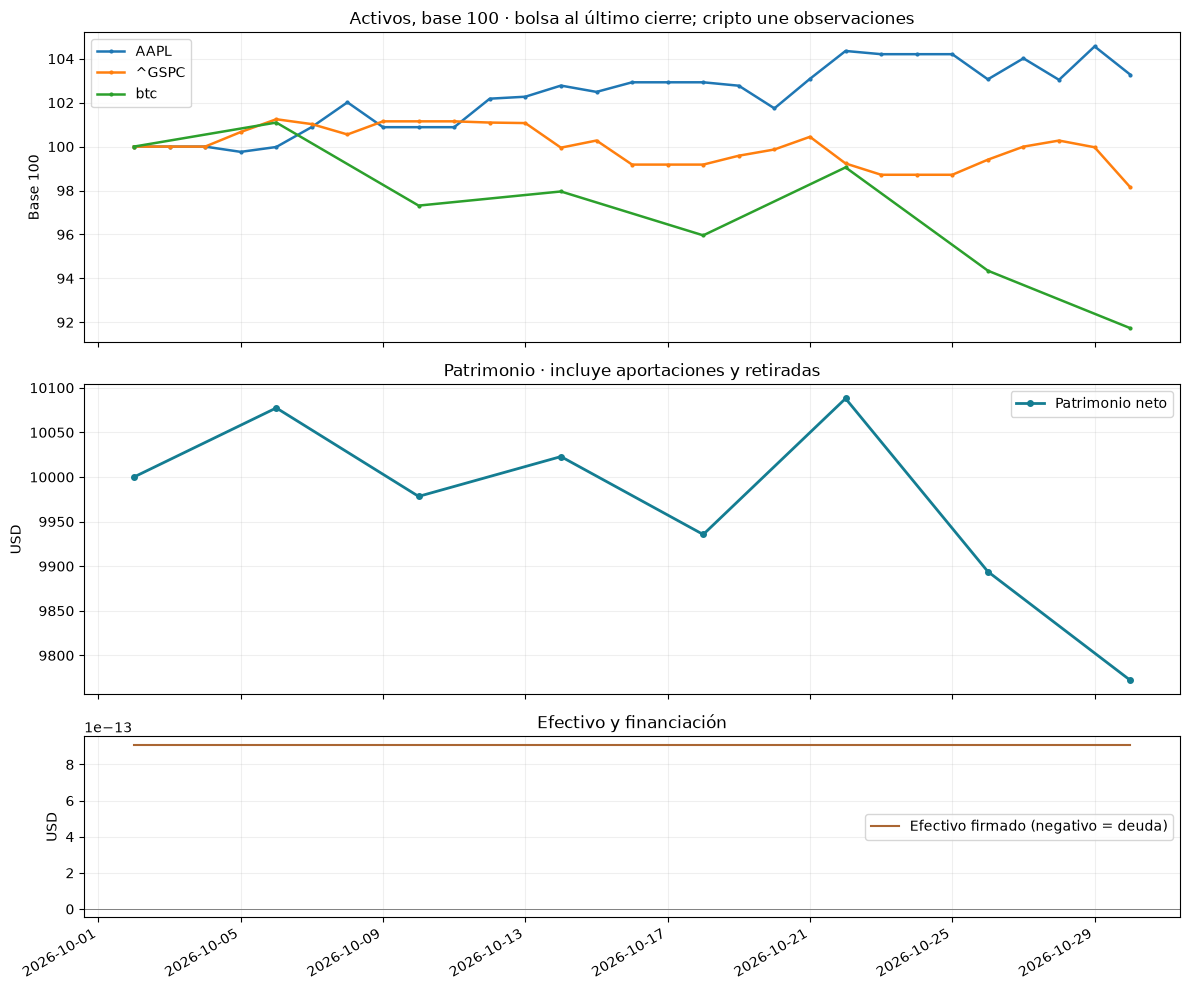

Días sin valoración completa: 21 de 29


In [16]:
history = pd.DataFrame({
    "Patrimonio USD": cartera.value(),
    "Efectivo USD": cartera.cash_history(),
    "Aportación / retirada USD": cartera.external_cash_flows(),
    "Rentabilidad diaria": cartera.returns(),
})
history = history.reindex(calendar[calendar >= selected_date])
table(history, money=["Patrimonio USD", "Efectivo USD", "Aportación / retirada USD"], percentages=["Rentabilidad diaria"])

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True,
                         gridspec_kw={"height_ratios": [1.2, 1.2, .7]})
plot_prices = observados.loc[selected_date:].copy()
for identifier, request in zip(ids, solicitudes):
    if request["type"] in ("stock", "index"):
        plot_prices[identifier] = plot_prices[identifier].ffill()
normalized = plot_prices.divide(plot_prices.loc[selected_date]).multiply(100)
for identifier in active_ids:
    line = normalized[identifier].dropna()
    axes[0].plot(line.index, line, linewidth=1.8, marker=".", markersize=4, label=identifier)
axes[0].set_title("Activos, base 100 · bolsa al último cierre; cripto une observaciones")
axes[0].set_ylabel("Base 100")
axes[0].legend()
observed_equity = history["Patrimonio USD"].dropna()
axes[1].plot(observed_equity.index, observed_equity, linewidth=2, marker="o",
             markersize=4, color="#147d92", label="Patrimonio neto")
axes[1].set_title("Patrimonio · incluye aportaciones y retiradas")
axes[1].set_ylabel("USD")
axes[1].legend()
axes[1].ticklabel_format(axis="y", style="plain", useOffset=False)
axes[2].step(history.index, history["Efectivo USD"], where="post", color="#aa6633",
             label="Efectivo firmado (negativo = deuda)")
axes[2].axhline(0, color="gray", linewidth=.7)
axes[2].set_title("Efectivo y financiación")
axes[2].set_ylabel("USD")
axes[2].legend()
for movement in movimientos:
    day = pd.Timestamp(movement["fecha"])
    axes[1].axvline(day, color="gray", alpha=.3, linewidth=.8, linestyle=":")
    axes[1].annotate(movement["tipo"], xy=(day, 1), xycoords=("data", "axes fraction"),
                     rotation=90, va="top", fontsize=7, color="#555555")
for ax in axes:
    ax.grid(alpha=.2)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

missing_days = int(history["Patrimonio USD"].isna().sum())
print(f"Días sin valoración completa: {missing_days} de {len(history)}")

## 9. Métricas con la frecuencia realmente disponible

Se utilizan fechas comunes para los activos. Si los intervalos son de cuatro días, la anualización usa 365/4 observaciones
por año. Si son irregulares, se utiliza el intervalo medio y se señala como **aproximación**.
La anualización de volatilidad presupone que la varianza escala con el tiempo; no es una garantía de riesgo futuro.

La rentabilidad histórica encadena retornos ajustados por aportaciones y retiradas (TWR): ingresar dinero no es ganar dinero.
Las estimaciones de rentabilidad esperada y volatilidad utilizan los pesos de la última valoración común, no los pesos
iniciales ni una rentabilidad histórica de estrategia. Excluyen costes de financiación.
El drawdown observado puede omitir caídas entre las fechas conocidas. Se necesitan al menos tres precios comunes
para estimar media y volatilidad. Con pocas observaciones, las estimaciones son poco robustas.

In [17]:
metric_rows = []
try:
    sampling = cartera.sampling_info()
    print(f"Precios comunes: {sampling['price_observations']}; retornos: {sampling['return_observations']}")
    print(f"Intervalo medio: {sampling['mean_days']:.2f} días")
    print(f"Factor anual: {sampling['periods_per_year']:.2f} observaciones/año")
    print("Muestreo regular" if sampling["regular"] else "Muestreo irregular: anualización aproximada con intervalo medio")
except ValueError:
    sampling = None
    print("Faltan observaciones comunes para las estimaciones de riesgo.")

error_messages = {
    "At least three common price observations are required": "Se necesitan al menos tres precios comunes",
    "Current risk metrics need a common valuation after the last movement": "Falta una valoración común posterior al último movimiento",
    "Sharpe is undefined when volatility is zero": "El Sharpe no está definido si la volatilidad es cero",
    "Growth cannot continue after zero or negative equity": "La rentabilidad encadenada no continúa tras agotar el patrimonio",
}
for name, calculation, unit in [
    ("Rentabilidad histórica TWR observada", lambda: cartera.growth().iloc[-1] - 1, "%"),
    ("Rentabilidad esperada anual", cartera.expected_return, "%"),
    ("Volatilidad anual", cartera.volatility, "%"),
    ("Sharpe (tipo libre de riesgo 0)", cartera.sharpe, "ratio"),
    ("Máximo drawdown observado", lambda: cartera.drawdown().min(), "%"),
]:
    try:
        value = calculation()
        formatted = f"{value:.2%}" if unit == "%" else f"{value:.3f}"
        metric_rows.append({"Métrica": name, "Resultado": formatted, "Estado": "Disponible"})
    except ValueError as error:
        metric_rows.append({"Métrica": name, "Resultado": "No calculada",
                            "Estado": error_messages.get(str(error), str(error))})
display(pd.DataFrame(metric_rows))
print(f"Comprobaciones iniciales correctas: {len(checks)}")
print(f"Movimientos posteriores comprobados: {len(movement_checks)}")
print("Para otra cartera, modifica la configuración y ejecuta de nuevo las secciones indicadas.")

Precios comunes: 8; retornos: 7
Intervalo medio: 4.00 días
Factor anual: 91.25 observaciones/año
Muestreo regular


,Métrica,Resultado,Estado
0,Rentabilidad histórica TWR observada,-2.28%,Disponible
1,Rentabilidad esperada anual,-26.96%,Disponible
2,Volatilidad anual,11.65%,Disponible
3,Sharpe (tipo libre de riesgo 0),-2.315,Disponible
4,Máximo drawdown observado,-3.13%,Disponible


Comprobaciones iniciales correctas: 5
Movimientos posteriores comprobados: 0
Para otra cartera, modifica la configuración y ejecuta de nuevo las secciones indicadas.
